In [2]:
!pip install openpyxl


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:
# Download Dry Bean Dataset directly

!wget -O Dry_Bean_Dataset.xlsx "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"


--2026-11-02 08:10:47--  https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘Dry_Bean_Dataset.xlsx’

Dry_Bean_Dataset.xl     [   <=>              ]   4.52M  9.43MB/s    in 0.5s    

2026-11-02 08:10:47 (9.43 MB/s) - ‘Dry_Bean_Dataset.xlsx’ saved [4738776]



In [5]:
import requests
import zipfile
import io
import os

url = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall("/content/DryBeanData")

print("Dataset downloaded and extracted successfully!")
print(os.listdir("/content/DryBeanData"))


Dataset downloaded and extracted successfully!
['DryBeanDataset']


In [6]:
import pandas as pd
import os

# Find the Excel file
files = os.listdir("/content/DryBeanData")

excel_file = [f for f in files if f.endswith(".xlsx")][0]

file_path = "/content/DryBeanData/" + excel_file

# Load dataset
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

IndexError: list index out of range

In [7]:
import os

print("Files inside DryBeanData:")

for root, dirs, files in os.walk("/content/DryBeanData"):
    for file in files:
        print(os.path.join(root, file))


Files inside DryBeanData:
/content/DryBeanData/DryBeanDataset/Dry_Bean_Dataset.arff
/content/DryBeanData/DryBeanDataset/Dry_Bean_Dataset.xlsx
/content/DryBeanData/DryBeanDataset/Dry_Bean_Dataset.txt


In [8]:
import pandas as pd

# Correct Excel file path
file_path = "/content/DryBeanData/DryBeanDataset/Dry_Bean_Dataset.xlsx"

# Load dataset
df = pd.read_excel(file_path)

print("Dry Bean Dataset Loaded Successfully!")

print("Number of Rows and Columns:", df.shape)

# Display first 5 records
display(df.head())

Dry Bean Dataset Loaded Successfully!
Number of Rows and Columns: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [9]:
# Dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  obje

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [10]:
# Dataset Shape

print("Total Number of Rows:", df.shape[0])
print("Total Number of Columns:", df.shape[1])
print("Column Names:")
print(df.columns.tolist())


Total Number of Rows: 13611
Total Number of Columns: 17
Column Names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


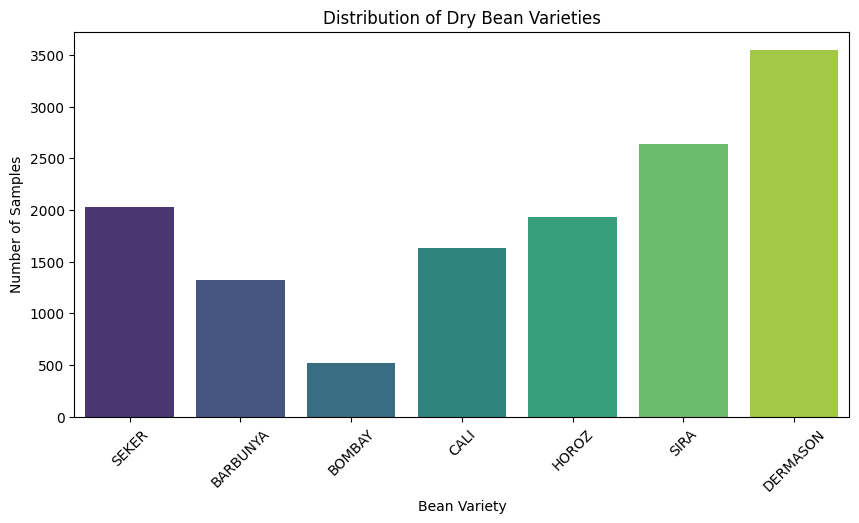

In [11]:
# Bean Class Distribution

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='Class', hue='Class',
              palette='viridis', legend=False)

plt.title("Distribution of Dry Bean Varieties")
plt.xlabel("Bean Variety")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)

plt.show()

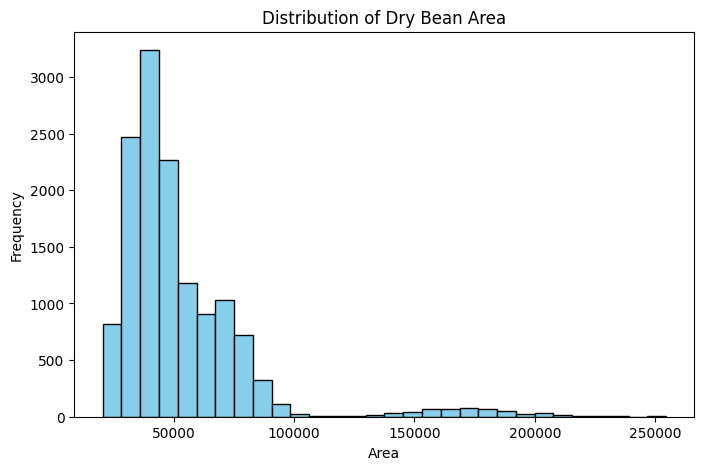

In [12]:
# Area Distribution

plt.figure(figsize=(8, 5))

plt.hist(df['Area'], bins=30, color='skyblue',
         edgecolor='black')

plt.title("Distribution of Dry Bean Area")
plt.xlabel("Area")
plt.ylabel("Frequency")

plt.show()

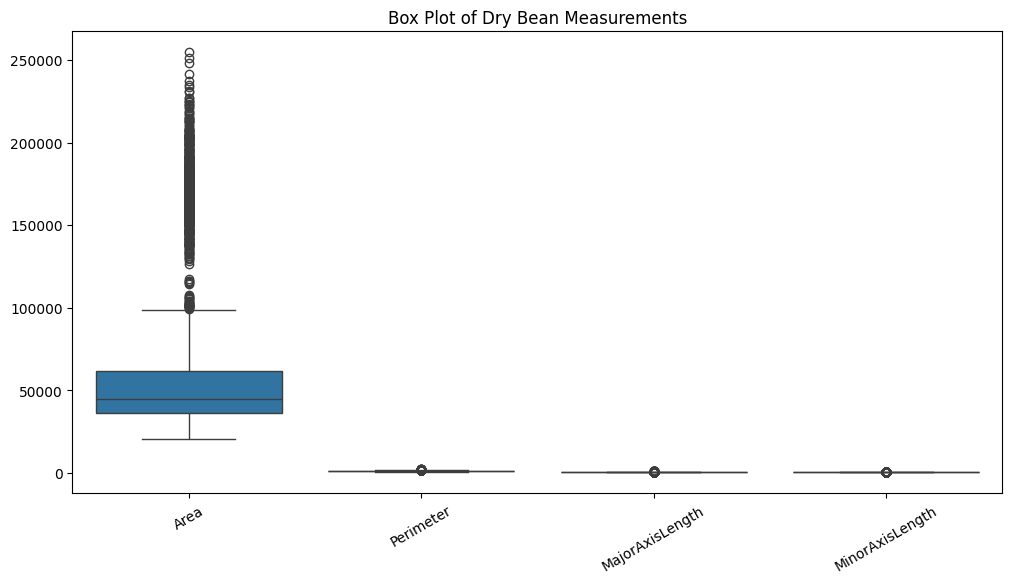

In [14]:
# Box Plot

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[['Area', 'Perimeter',
                     'MajorAxisLength',
                     'MinorAxisLength']])

plt.title("Box Plot of Dry Bean Measurements")
plt.xticks(rotation=30)

plt.show()


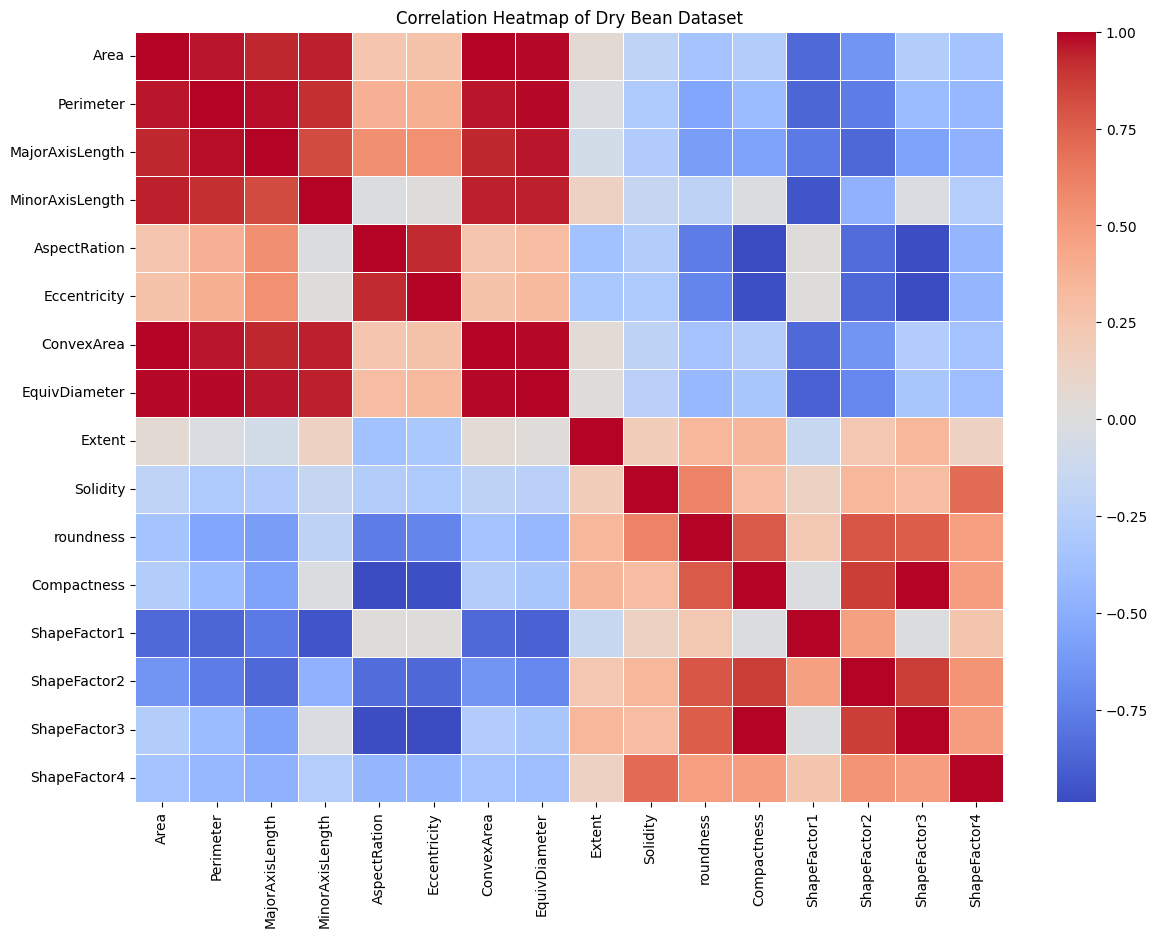

In [15]:
# Correlation Heatmap

plt.figure(figsize=(14, 10))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(correlation, cmap='coolwarm',
            annot=False, linewidths=0.5)

plt.title("Correlation Heatmap of Dry Bean Dataset")

plt.show()


In [16]:
# Save EDA summary

print("EDA COMPLETED SUCCESSFULLY")

print("\nDataset Information:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nBean Varieties:")
print(df['Class'].value_counts())

print("\nMissing Values:")
print(df.isnull().sum().sum())

EDA COMPLETED SUCCESSFULLY

Dataset Information:
Rows: 13611
Columns: 17

Bean Varieties:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Missing Values:
0


In [17]:
# Check missing values

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())


Missing Values in Each Column:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Total Missing Values: 0


In [18]:
# Check and remove duplicates

print("Duplicates Before Removal:",
      df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates After Removal:",
      df.duplicated().sum())

print("Updated Dataset Shape:", df.shape)

Duplicates Before Removal: 68
Duplicates After Removal: 0
Updated Dataset Shape: (13543, 17)


In [20]:
# Handle missing values

numeric_cols = df.select_dtypes(
    include=np.number
).columns

df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

df['Class'] = df['Class'].fillna(
    df['Class'].mode()[0]
)

print("Missing values handled successfully!")
print("Remaining Missing Values:",
      df.isnull().sum().sum())

Missing values handled successfully!
Remaining Missing Values: 0


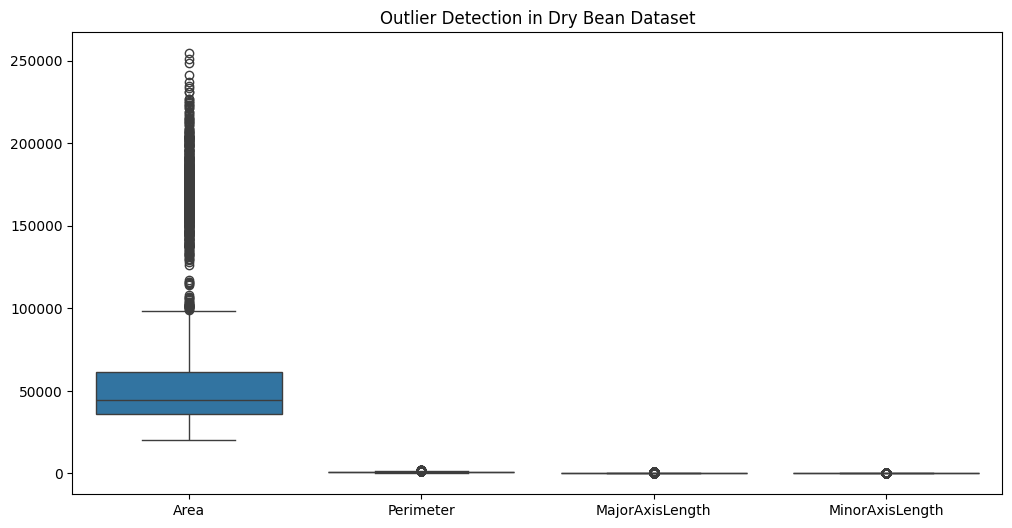

In [21]:
# Outlier Detection

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[['Area', 'Perimeter',
                     'MajorAxisLength',
                     'MinorAxisLength']])

plt.title("Outlier Detection in Dry Bean Dataset")
plt.show()

In [22]:
# Min-Max Normalization

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X = df.drop('Class', axis=1)
y = df['Class']

X_minmax = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

print("Min-Max Normalization Completed!")
display(X_minmax.head())

Min-Max Normalization Completed!


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,0.034053,0.058574,0.044262,0.152142,0.122612,0.477797,0.033107,0.070804,0.671024,0.922824,0.934823,0.786733,0.593432,0.833049,0.750996,0.980620
1,0.035500,0.077557,0.030479,0.178337,0.051577,0.278472,0.034991,0.073577,0.735504,0.871514,0.793138,0.903549,0.547447,0.967315,0.884987,0.974979
2,0.038259,0.068035,0.052633,0.158190,0.131521,0.496448,0.037126,0.078816,0.716671,0.932141,0.914511,0.773514,0.582016,0.800942,0.736200,0.987196
3,0.040940,0.082942,0.048548,0.177691,0.091623,0.403864,0.041389,0.083854,0.731365,0.761614,0.826871,0.829912,0.552408,0.854744,0.799846,0.893675
4,0.041504,0.065313,0.032862,0.200679,0.025565,0.165680,0.040123,0.084906,0.700538,0.949832,0.988408,0.951583,0.510741,1.000000,0.941770,0.989116


In [23]:
# Z-score Standardization

standard_scaler = StandardScaler()

X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X),
    columns=X.columns
)

print("Z-score Standardization Completed!")
display(X_standard.head())

Z-score Standardization Completed!


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,-0.838800,-1.139663,-1.301976,-0.632111,-1.565363,-2.182833,-0.839489,-1.060491,0.287981,0.366476,1.420346,1.838628,0.681918,2.398280,1.924811,0.838679
1,-0.827266,-1.010529,-1.391169,-0.435758,-1.972460,-3.685504,-0.824175,-1.041410,0.697598,-0.465886,0.224987,2.497622,0.369552,3.097471,2.691446,0.771141
2,-0.805287,-1.075303,-1.247807,-0.586775,-1.514305,-2.042229,-0.806818,-1.005357,0.577958,0.517614,1.248979,1.764053,0.604373,2.231086,1.840150,0.917418
3,-0.783920,-0.973894,-1.274241,-0.440595,-1.742960,-2.740196,-0.772170,-0.970686,0.671302,-2.248692,0.509588,2.082211,0.403254,2.511258,2.204306,-0.202373
4,-0.779429,-1.093821,-1.375750,-0.268281,-2.121534,-4.535823,-0.782457,-0.963445,0.475476,0.804605,1.872434,2.768598,0.120215,3.267675,3.016333,0.940406


In [24]:
# Compare Normalization Methods

comparison = pd.DataFrame({
    'Original Mean': X.mean(),
    'MinMax Mean': X_minmax.mean(),
    'ZScore Mean': X_standard.mean()
})

display(comparison)

,Original Mean,MinMax Mean,ZScore Mean
Area,53048.460385,0.139321,-3.357804e-17
Perimeter,854.993406,0.226106,2.686243e-16
MajorAxisLength,319.895602,0.245461,1.678902e-16
MinorAxisLength,202.365321,0.236470,-1.007341e-16
AspectRation,1.581075,0.395754,8.394509e-16
Eccentricity,0.750315,0.767344,-1.053511e-15
ConvexArea,53767.986709,0.136386,1.007341e-16
EquivDiameter,253.034094,0.224904,-3.693584e-16
Extent,0.749829,0.625691,-2.854133e-16
Solidity,0.987152,0.900233,1.309543e-14


Feature Importance:


,0
Perimeter,0.095560
ShapeFactor3,0.095106
Compactness,0.095041
ShapeFactor1,0.091850
MinorAxisLength,0.075028
ConvexArea,0.070071
MajorAxisLength,0.069957
EquivDiameter,0.069086
Eccentricity,0.064122
roundness,0.059565


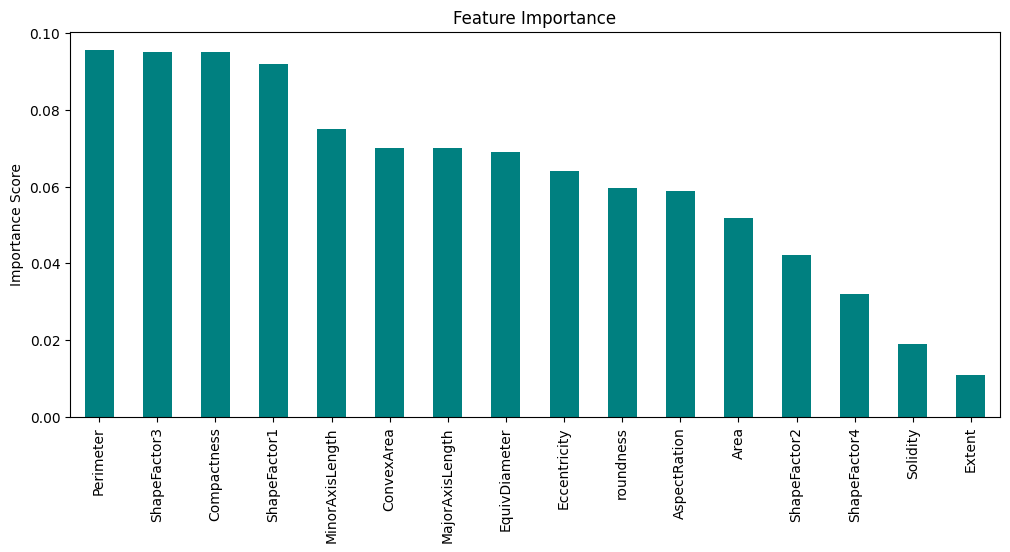

In [25]:
# Feature Selection

from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
display(importance)

importance.plot(
    kind='bar',
    figsize=(12, 5),
    color='teal'
)

plt.title("Feature Importance")
plt.ylabel("Importance Score")
plt.show()

In [26]:
# PCA

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_standard)

print("PCA Completed!")
print("Original Features:", X.shape[1])
print("Reduced Features:", X_pca.shape[1])

print("Explained Variance Ratio:",
      pca.explained_variance_ratio_)

print("Total Explained Variance:",
      pca.explained_variance_ratio_.sum())

PCA Completed!
Original Features: 16
Reduced Features: 2
Explained Variance Ratio: [0.55546808 0.26360789]
Total Explained Variance: 0.8190759716525313


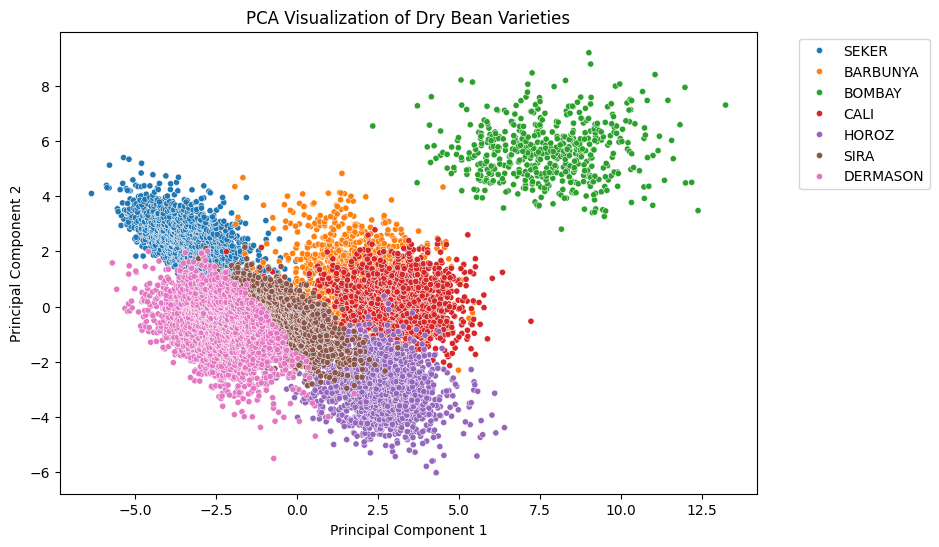

In [27]:
# PCA Visualization

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=y,
    palette='tab10',
    s=20
)

plt.title("PCA Visualization of Dry Bean Varieties")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(bbox_to_anchor=(1.05, 1))
plt.show()

In [28]:
# Step 19: Prepare the dataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Separate input and output
X = df.drop('Class', axis=1)
y = df['Class']

# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Standardize features without data leakage
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training and Testing Data Prepared!")
print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training and Testing Data Prepared!
Training Records: 10834
Testing Records: 2709


In [29]:
# Step 20: Decision Tree

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_prediction = dt_model.predict(X_test)

from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(
    y_test, dt_prediction
)

print("Decision Tree Classification")
print("Accuracy:", dt_accuracy * 100, "%")

Decision Tree Classification
Accuracy: 89.66408268733849 %


In [30]:
# Step 21: Rule-Based Classification

from sklearn.tree import export_text

rule_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

rule_model.fit(X_train, y_train)

rule_prediction = rule_model.predict(X_test)

rule_accuracy = accuracy_score(
    y_test, rule_prediction
)

print("Rule-Based Classification")
print("Accuracy:", rule_accuracy * 100, "%")

# Display IF-THEN rules
rules = export_text(
    rule_model,
    feature_names=list(X.columns)
)

print("\nGenerated Classification Rules:")
print(rules)

Rule-Based Classification
Accuracy: 81.57991878922111 %

Generated Classification Rules:
|--- MajorAxisLength <= 280.70
|   |--- ShapeFactor1 <= 0.01
|   |   |--- ShapeFactor3 <= 0.73
|   |   |   |--- roundness <= 0.93
|   |   |   |   |--- class: 6
|   |   |   |--- roundness >  0.93
|   |   |   |   |--- class: 3
|   |   |--- ShapeFactor3 >  0.73
|   |   |   |--- ShapeFactor4 <= 1.00
|   |   |   |   |--- class: 5
|   |   |   |--- ShapeFactor4 >  1.00
|   |   |   |   |--- class: 5
|   |--- ShapeFactor1 >  0.01
|   |   |--- MinorAxisLength <= 176.86
|   |   |   |--- Perimeter <= 704.89
|   |   |   |   |--- class: 3
|   |   |   |--- Perimeter >  704.89
|   |   |   |   |--- class: 3
|   |   |--- MinorAxisLength >  176.86
|   |   |   |--- ShapeFactor3 <= 0.77
|   |   |   |   |--- class: 3
|   |   |   |--- ShapeFactor3 >  0.77
|   |   |   |   |--- class: 5
|--- MajorAxisLength >  280.70
|   |--- Compactness <= 0.73
|   |   |--- MinorAxisLength <= 215.31
|   |   |   |--- ShapeFactor1 <= 0.01
|

In [31]:
# Step 22: KNN Classification

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

knn_prediction = knn_model.predict(
    X_test_scaled
)

knn_accuracy = accuracy_score(
    y_test, knn_prediction
)

print("KNN Classification")
print("Accuracy:", knn_accuracy * 100, "%")

KNN Classification
Accuracy: 91.54669619785899 %


Classification Performance Comparison


,Algorithm,Accuracy (%)
0,Decision Tree,89.664083
1,Rule-Based Classification,81.579919
2,KNN,91.546696


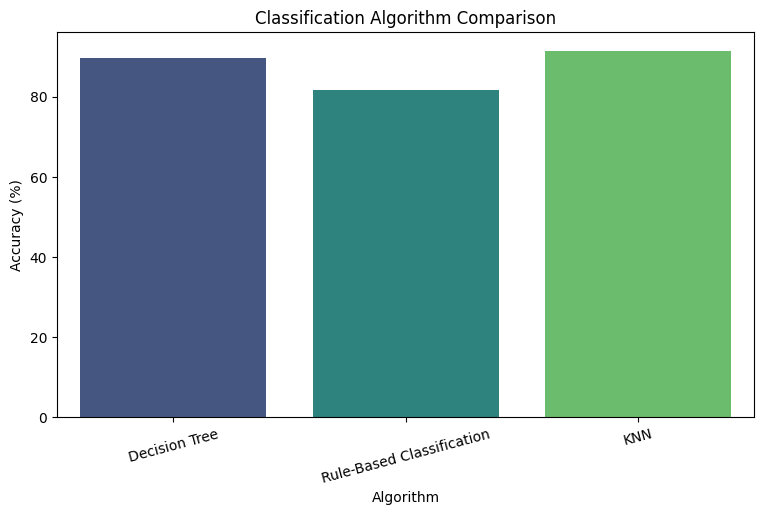

In [32]:
# Algorithm Accuracy Comparison

results = pd.DataFrame({
    'Algorithm': [
        'Decision Tree',
        'Rule-Based Classification',
        'KNN'
    ],
    'Accuracy (%)': [
        dt_accuracy * 100,
        rule_accuracy * 100,
        knn_accuracy * 100
    ]
})

print("Classification Performance Comparison")
display(results)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x='Algorithm',
    y='Accuracy (%)',
    hue='Algorithm',
    legend=False,
    palette='viridis'
)

plt.title("Classification Algorithm Comparison")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=15)
plt.show()

In [33]:
# Classification Reports

from sklearn.metrics import classification_report

print("DECISION TREE REPORT")
print(classification_report(
    y_test,
    dt_prediction,
    target_names=label_encoder.classes_
))

print("\nRULE-BASED CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    rule_prediction,
    target_names=label_encoder.classes_
))

print("\nKNN CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    knn_prediction,
    target_names=label_encoder.classes_
))

DECISION TREE REPORT
              precision    recall  f1-score   support

    BARBUNYA       0.88      0.90      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.91      0.91       326
    DERMASON       0.89      0.91      0.90       709
       HOROZ       0.95      0.92      0.94       372
       SEKER       0.91      0.94      0.92       406
        SIRA       0.84      0.81      0.82       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.90      2709


RULE-BASED CLASSIFICATION REPORT
              precision    recall  f1-score   support

    BARBUNYA       0.00      0.00      0.00       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.52      0.98      0.68       326
    DERMASON       0.88      0.92      0.90       709
       HOROZ       0.98      0.87      0.92       372
       SEKER       0.93

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


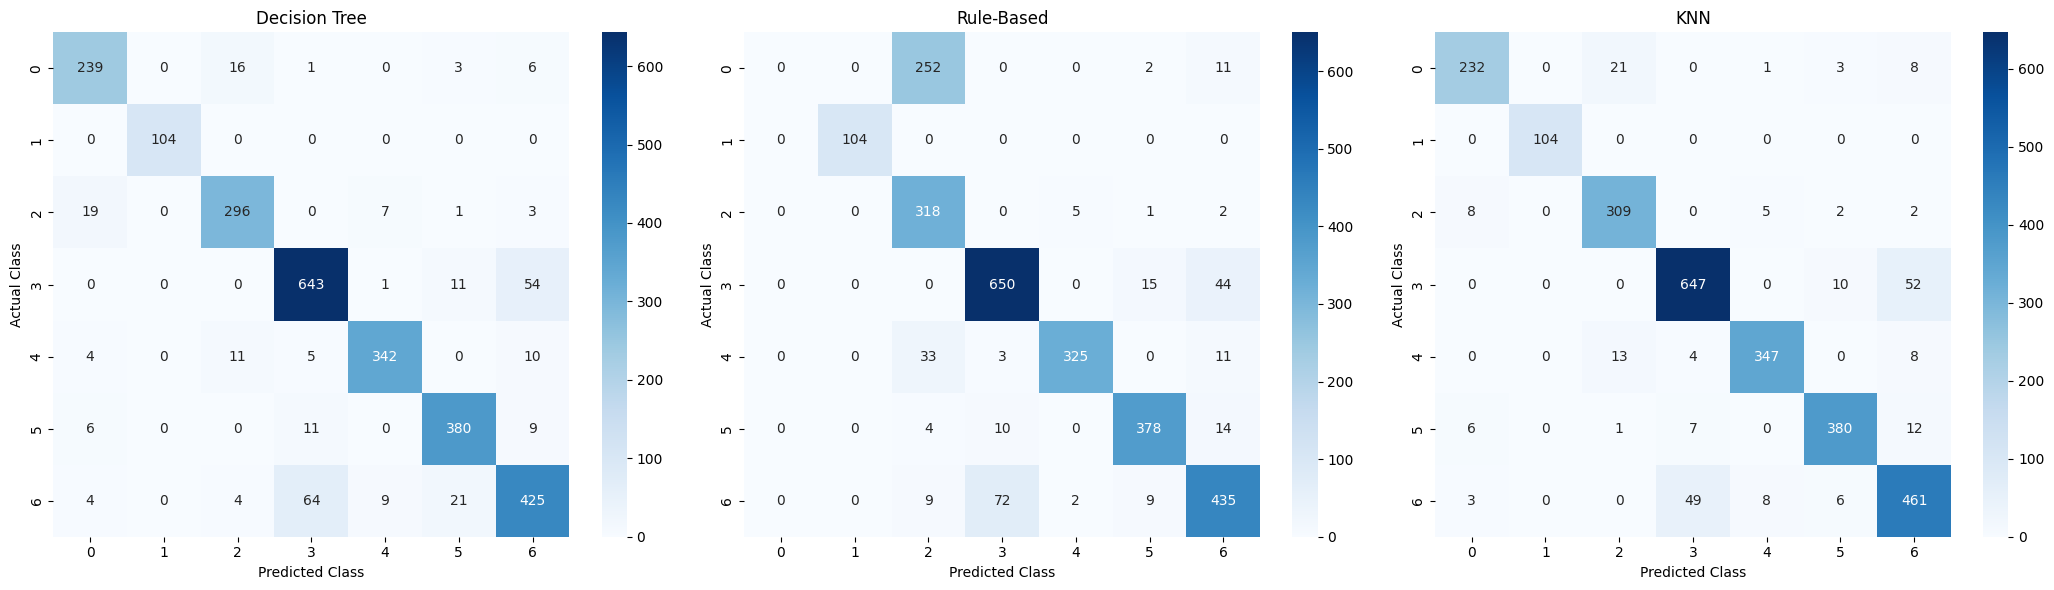

In [34]:
# Confusion Matrices

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

predictions = [
    dt_prediction,
    rule_prediction,
    knn_prediction
]

names = [
    'Decision Tree',
    'Rule-Based',
    'KNN'
]

for ax, prediction, name in zip(
    axes, predictions, names
):
    cm = confusion_matrix(y_test, prediction)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [35]:
# Step 26: Select numerical attributes

association_df = df[
    ['Area', 'Perimeter', 'MajorAxisLength',
     'MinorAxisLength', 'AspectRation']
].copy()

print("Selected Attributes:")
display(association_df.head())

Selected Attributes:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation
0,28395,610.291,208.178117,173.888747,1.197191
1,28734,638.018,200.524796,182.734419,1.097356
2,29380,624.110,212.826130,175.931143,1.209713
3,30008,645.884,210.557999,182.516516,1.153638
4,30140,620.134,201.847882,190.279279,1.060798


In [36]:
# Step 27: Convert numerical values into categories

categorical_df = pd.DataFrame(index=association_df.index)

for column in association_df.columns:
    categorical_df[column] = pd.qcut(
        association_df[column],
        q=3,
        labels=['Small', 'Medium', 'Large'],
        duplicates='drop'
    )

print("Numerical Data Converted into Categories!")
display(categorical_df.head())

Numerical Data Converted into Categories!


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation
0,Small,Small,Small,Small,Small
1,Small,Small,Small,Medium,Small
2,Small,Small,Small,Small,Small
3,Small,Small,Small,Medium,Small
4,Small,Small,Small,Medium,Small


In [38]:
# Step 29: Apriori Algorithm

from mlxtend.frequent_patterns import apriori

frequent_itemsets_apriori = apriori(
    encoded_df,
    min_support=0.05,
    use_colnames=True
)

print("Apriori Frequent Itemsets:")
display(
    frequent_itemsets_apriori.sort_values(
        by='support',
        ascending=False
    ).head(15)
)

Apriori Frequent Itemsets:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
0,0.333383,(Area=Large)
2,0.333383,(Area=Small)
6,0.333383,(MajorAxisLength=Large)
5,0.333383,(AspectRation=Small)
12,0.333383,(Perimeter=Large)
14,0.333383,(Perimeter=Small)
11,0.333383,(MinorAxisLength=Small)
8,0.333383,(MajorAxisLength=Small)
10,0.333309,(MinorAxisLength=Medium)
9,0.333309,(MinorAxisLength=Large)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [37]:
# Step 28: One-Hot Encoding

from mlxtend.preprocessing import TransactionEncoder

transactions = []

for _, row in categorical_df.iterrows():
    transaction = [
        f"{column}={value}"
        for column, value in row.items()
    ]
    transactions.append(transaction)

te = TransactionEncoder()

transaction_array = te.fit(
    transactions
).transform(transactions)

encoded_df = pd.DataFrame(
    transaction_array,
    columns=te.columns_
)

print("Transaction Encoding Completed!")
display(encoded_df.head())

Transaction Encoding Completed!


,Area=Large,Area=Medium,Area=Small,AspectRation=Large,AspectRation=Medium,AspectRation=Small,MajorAxisLength=Large,MajorAxisLength=Medium,MajorAxisLength=Small,MinorAxisLength=Large,MinorAxisLength=Medium,MinorAxisLength=Small,Perimeter=Large,Perimeter=Medium,Perimeter=Small
0,False,False,True,False,False,True,False,False,True,False,False,True,False,False,True
1,False,False,True,False,False,True,False,False,True,False,True,False,False,False,True
2,False,False,True,False,False,True,False,False,True,False,False,True,False,False,True
3,False,False,True,False,False,True,False,False,True,False,True,False,False,False,True
4,False,False,True,False,False,True,False,False,True,False,True,False,False,False,True


In [39]:
# Step 29: Apriori Algorithm

from mlxtend.frequent_patterns import apriori

frequent_itemsets_apriori = apriori(
    encoded_df,
    min_support=0.05,
    use_colnames=True
)

print("Apriori Frequent Itemsets:")
display(
    frequent_itemsets_apriori.sort_values(
        by='support',
        ascending=False
    ).head(15)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Apriori Frequent Itemsets:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
0,0.333383,(Area=Large)
2,0.333383,(Area=Small)
6,0.333383,(MajorAxisLength=Large)
5,0.333383,(AspectRation=Small)
12,0.333383,(Perimeter=Large)
14,0.333383,(Perimeter=Small)
11,0.333383,(MinorAxisLength=Small)
8,0.333383,(MajorAxisLength=Small)
10,0.333309,(MinorAxisLength=Medium)
9,0.333309,(MinorAxisLength=Large)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [40]:
# Step 30: Association Rules

from mlxtend.frequent_patterns import association_rules

rules_apriori = association_rules(
    frequent_itemsets_apriori,
    metric="confidence",
    min_threshold=0.5
)

print("Apriori Association Rules:")

display(
    rules_apriori[
        ['antecedents', 'consequents',
         'support', 'confidence', 'lift']
    ].head(15)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Apriori Association Rules:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
0,(AspectRation=Large),(Area=Large),0.213837,0.641560,1.924395
1,(Area=Large),(AspectRation=Large),0.213837,0.641417,1.924395
2,(MajorAxisLength=Large),(Area=Large),0.298974,0.896788,2.689968
3,(Area=Large),(MajorAxisLength=Large),0.298974,0.896788,2.689968
4,(Area=Large),(MinorAxisLength=Large),0.265082,0.795127,2.385558
5,(MinorAxisLength=Large),(Area=Large),0.265082,0.795304,2.385558
6,(Perimeter=Large),(Area=Large),0.321716,0.965006,2.894589
7,(Area=Large),(Perimeter=Large),0.321716,0.965006,2.894589
8,(MajorAxisLength=Medium),(Area=Medium),0.251864,0.755817,2.268119
9,(Area=Medium),(MajorAxisLength=Medium),0.251864,0.755817,2.268119


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [41]:
# Step 31: FP-Growth Algorithm

from mlxtend.frequent_patterns import fpgrowth

frequent_itemsets_fp = fpgrowth(
    encoded_df,
    min_support=0.05,
    use_colnames=True
)

print("FP-Growth Frequent Itemsets:")

display(
    frequent_itemsets_fp.sort_values(
        by='support',
        ascending=False
    ).head(15)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

FP-Growth Frequent Itemsets:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
0,0.333383,(Perimeter=Small)
1,0.333383,(MinorAxisLength=Small)
2,0.333383,(MajorAxisLength=Small)
3,0.333383,(AspectRation=Small)
4,0.333383,(Area=Small)
14,0.333383,(MajorAxisLength=Large)
13,0.333383,(Area=Large)
10,0.333383,(Perimeter=Large)
12,0.333309,(AspectRation=Large)
7,0.333309,(MinorAxisLength=Large)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [42]:
# Step 32: FP-Growth Rules

rules_fp = association_rules(
    frequent_itemsets_fp,
    metric="confidence",
    min_threshold=0.5
)

print("FP-Growth Association Rules:")

display(
    rules_fp[
        ['antecedents', 'consequents',
         'support', 'confidence', 'lift']
    ].head(15)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

FP-Growth Association Rules:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
0,(Perimeter=Small),(MinorAxisLength=Small),0.234808,0.704319,2.112645
1,(MinorAxisLength=Small),(Perimeter=Small),0.234808,0.704319,2.112645
2,(Perimeter=Small),(MajorAxisLength=Small),0.300155,0.900332,2.700598
3,(MajorAxisLength=Small),(Perimeter=Small),0.300155,0.900332,2.700598
4,(MinorAxisLength=Small),(MajorAxisLength=Small),0.206158,0.618383,1.854876
5,(MajorAxisLength=Small),(MinorAxisLength=Small),0.206158,0.618383,1.854876
6,"(Perimeter=Small, MinorAxisLength=Small)",(MajorAxisLength=Small),0.205346,0.874528,2.623198
7,"(Perimeter=Small, MajorAxisLength=Small)",(MinorAxisLength=Small),0.205346,0.684133,2.052095
8,"(MinorAxisLength=Small, MajorAxisLength=Small)",(Perimeter=Small),0.205346,0.996060,2.987739
9,(Perimeter=Small),"(MinorAxisLength=Small, MajorAxisLength=Small)",0.205346,0.615947,2.987739


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Apriori vs FP-Growth Comparison


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Algorithm,Frequent Itemsets,Association Rules
0,Apriori,184,651
1,FP-Growth,184,651


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

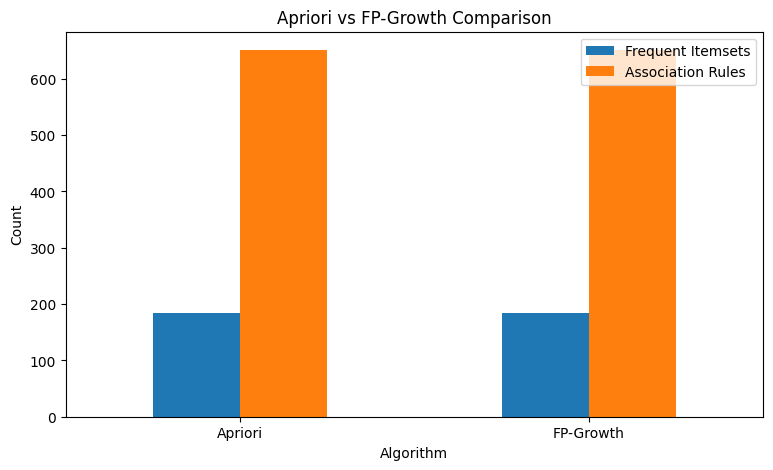

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [43]:
# Step 33: Algorithm Comparison

comparison = pd.DataFrame({
    'Algorithm': ['Apriori', 'FP-Growth'],
    'Frequent Itemsets': [
        len(frequent_itemsets_apriori),
        len(frequent_itemsets_fp)
    ],
    'Association Rules': [
        len(rules_apriori),
        len(rules_fp)
    ]
})

print("Apriori vs FP-Growth Comparison")
display(comparison)

comparison.set_index('Algorithm').plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title("Apriori vs FP-Growth Comparison")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

In [44]:
# Step 34: Prepare clustering data

from sklearn.preprocessing import StandardScaler

X_cluster = df.drop('Class', axis=1)

cluster_scaler = StandardScaler()

X_scaled = cluster_scaler.fit_transform(X_cluster)

print("Clustering Data Prepared Successfully!")
print("Number of Records:", X_scaled.shape[0])
print("Number of Features:", X_scaled.shape[1])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Clustering Data Prepared Successfully!
Number of Records: 13543
Number of Features: 16


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [45]:
# Step 35: K-Means Clustering

from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Completed!")
print("Cluster Labels:")
print(kmeans_labels[:20])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

K-Means Clustering Completed!
Cluster Labels:
[5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [46]:
# Step 35: K-Means Clustering

from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Completed!")
print("Cluster Labels:")
print(kmeans_labels[:20])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

K-Means Clustering Completed!
Cluster Labels:
[5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

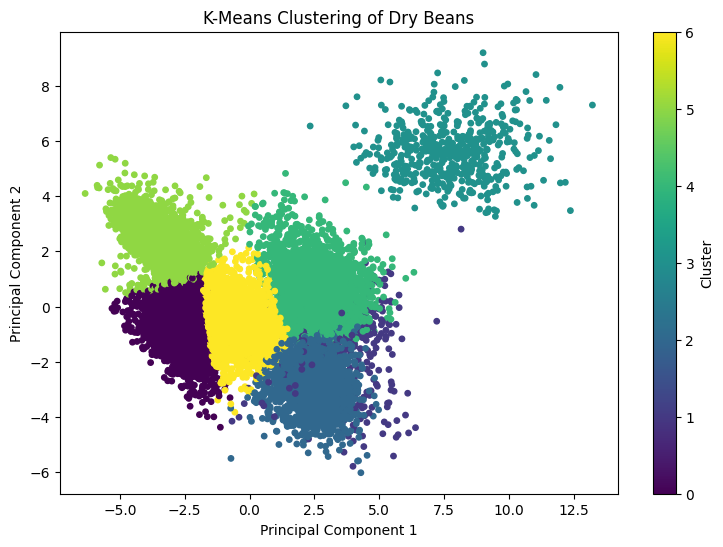

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [47]:
# Step 36: K-Means Visualization

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=15
)

plt.title("K-Means Clustering of Dry Beans")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")

plt.show()

In [ ]:


# Step 38: Dendrogram

from scipy.cluster.hierarchy import dendrogram, linkage

sample_data = X_scaled[:100]

linked = linkage(sample_data, method='ward')

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Bean Records")
plt.ylabel("Distance")

plt.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

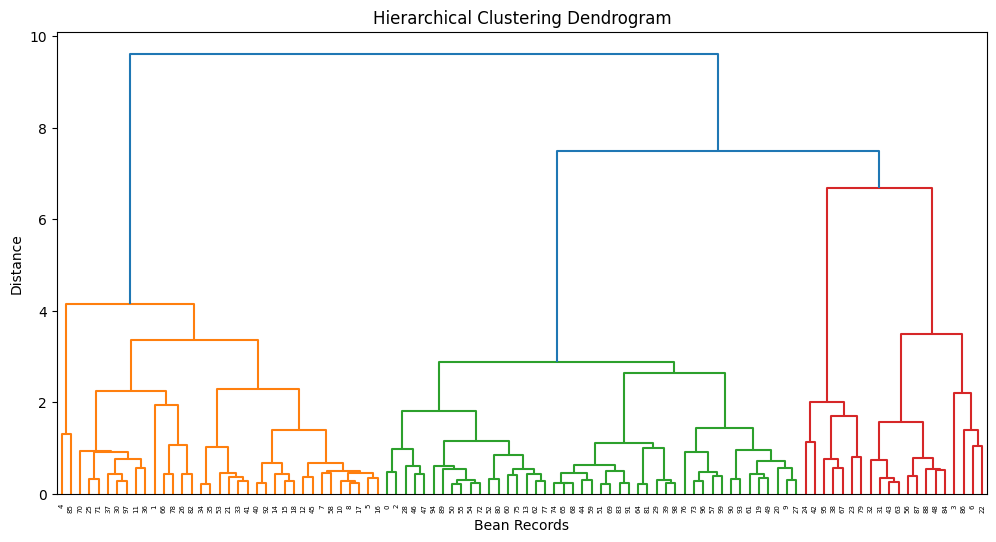

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [50]:
# Step 38: Dendrogram

from scipy.cluster.hierarchy import dendrogram, linkage

sample_data = X_scaled[:100]

linked = linkage(sample_data, method='ward')

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Bean Records")
plt.ylabel("Distance")

plt.show()

In [51]:
# Step 39: DBSCAN Clustering

from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=2.0,
    min_samples=10
)

dbscan_labels = dbscan.fit_predict(X_scaled)

print("DBSCAN Clustering Completed!")

print("Cluster Labels:")
print(dbscan_labels[:20])

print("Number of Clusters:",
      len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))

print("Noise Points:",
      list(dbscan_labels).count(-1))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

DBSCAN Clustering Completed!
Cluster Labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Number of Clusters: 1
Noise Points: 72


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

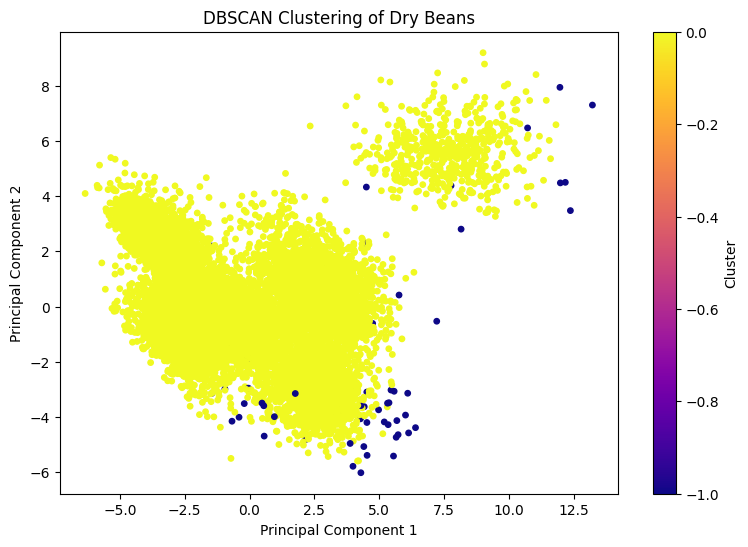

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [52]:
# Step 40: DBSCAN Visualization

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap='plasma',
    s=15
)

plt.title("DBSCAN Clustering of Dry Beans")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")

plt.show()

In [1]:
# Step 40: DBSCAN Visualization

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap='plasma',
    s=15
)

plt.title("DBSCAN Clustering of Dry Beans")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")

plt.show()

NameError: name 'plt' is not defined

In [2]:
# Step 41: Clustering Performance Comparison

from sklearn.metrics import silhouette_score

labels_dict = {
    'K-Means': kmeans_labels,
    'Hierarchical': hierarchical_labels,
    'DBSCAN': dbscan_labels
}

for name, labels in labels_dict.items():

    unique_labels = set(labels)

    if -1 in unique_labels:
        unique_labels.remove(-1)

    if 2 <= len(unique_labels) < len(labels):
        score = silhouette_score(
            X_scaled,
            labels
        )
        print(name, "Silhouette Score:", round(score, 4))
    else:
        print(name, "Silhouette Score: Not applicable")

NameError: name 'kmeans_labels' is not defined

In [3]:
# Re-create clustering variables

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

# Prepare data
X_cluster = df.drop('Class', axis=1)

cluster_scaler = StandardScaler()
X_scaled = cluster_scaler.fit_transform(X_cluster)

# K-Means
kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Hierarchical Clustering
hierarchical = AgglomerativeClustering(
    n_clusters=7,
    linkage='ward'
)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# DBSCAN
dbscan = DBSCAN(
    eps=2.0,
    min_samples=10
)
dbscan_labels = dbscan.fit_predict(X_scaled)

print("All Three Clustering Algorithms Executed Successfully!")

NameError: name 'df' is not defined

In [4]:
# Reload Dry Bean Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/content/DryBeanData/DryBeanDataset/Dry_Bean_Dataset.xlsx"

df = pd.read_excel(file_path)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [5]:
# Re-run all clustering algorithms

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

X_cluster = df.drop('Class', axis=1)

cluster_scaler = StandardScaler()
X_scaled = cluster_scaler.fit_transform(X_cluster)

# K-Means
kmeans = KMeans(n_clusters=7, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Hierarchical
hierarchical = AgglomerativeClustering(n_clusters=7)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# DBSCAN
dbscan = DBSCAN(eps=2.0, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_scaled)

print("All clustering algorithms executed successfully!")

All clustering algorithms executed successfully!


In [6]:
from sklearn.metrics import silhouette_score

labels_dict = {
    'K-Means': kmeans_labels,
    'Hierarchical': hierarchical_labels,
    'DBSCAN': dbscan_labels
}

for name, labels in labels_dict.items():

    unique_labels = set(labels)

    if -1 in unique_labels:
        unique_labels.remove(-1)

    if 2 <= len(unique_labels) < len(labels):
        score = silhouette_score(X_scaled, labels)
        print(name, "Silhouette Score:", round(score, 4))
    else:
        print(name, "Silhouette Score: Not applicable")

K-Means Silhouette Score: 0.3094
Hierarchical Silhouette Score: 0.2839
DBSCAN Silhouette Score: Not applicable


In [7]:
cluster_comparison = pd.DataFrame({
    'Actual_Class': df['Class'].values,
    'KMeans_Cluster': kmeans_labels,
    'Hierarchical_Cluster': hierarchical_labels,
    'DBSCAN_Cluster': dbscan_labels
})

print("Clustering Comparison:")
display(cluster_comparison.head(20))

Clustering Comparison:


,Actual_Class,KMeans_Cluster,Hierarchical_Cluster,DBSCAN_Cluster
0,SEKER,2,3,0
1,SEKER,2,3,0
2,SEKER,2,3,0
3,SEKER,2,3,0
4,SEKER,2,3,0
5,SEKER,2,3,0
6,SEKER,2,3,0
7,SEKER,2,3,0
8,SEKER,2,3,0
9,SEKER,2,3,0


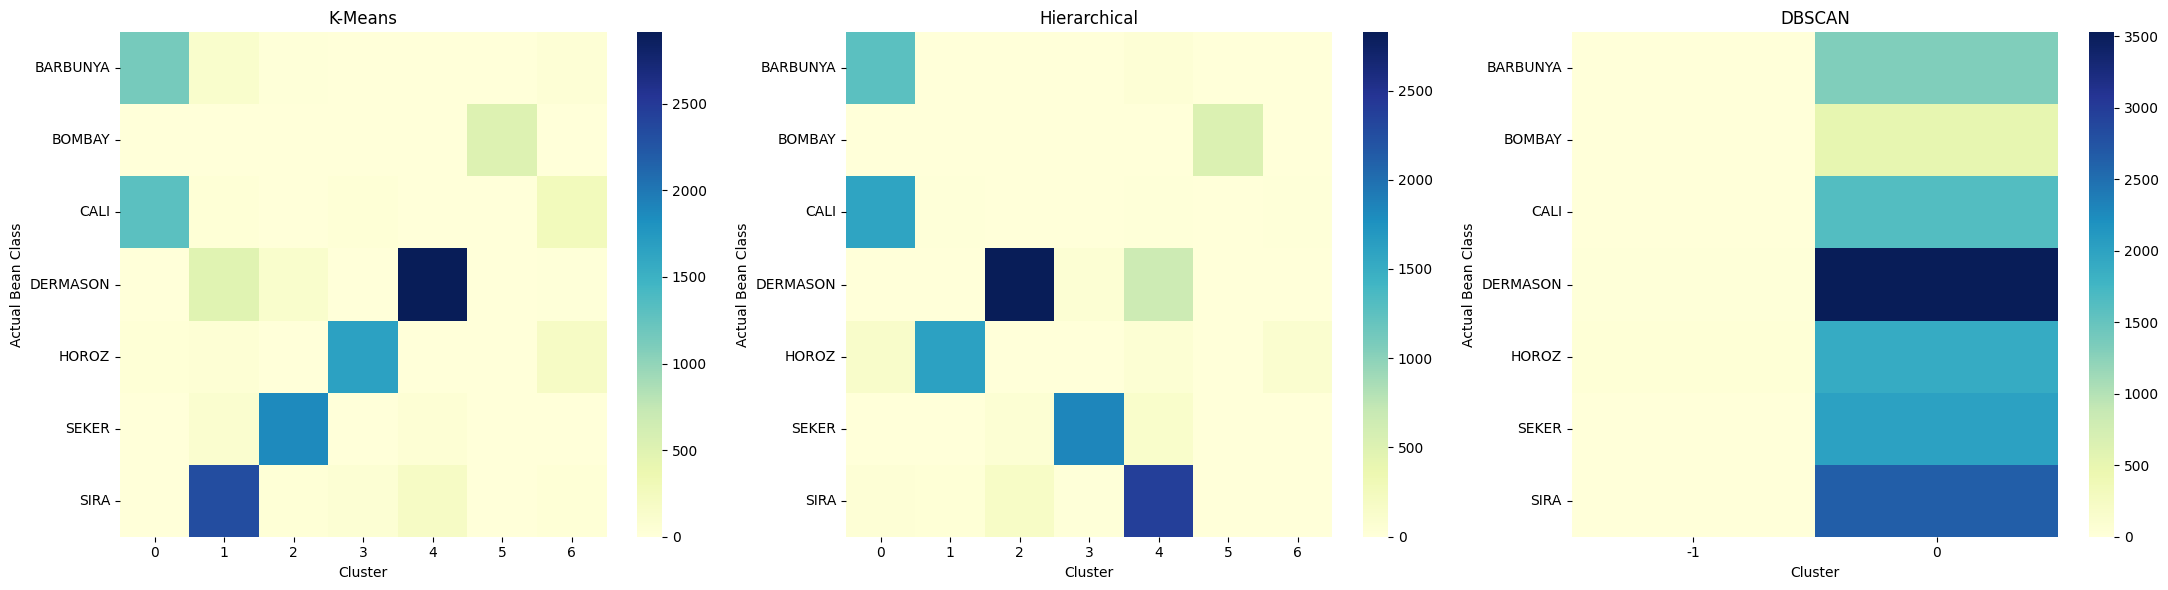

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

algorithms = [
    ('KMeans_Cluster', 'K-Means'),
    ('Hierarchical_Cluster', 'Hierarchical'),
    ('DBSCAN_Cluster', 'DBSCAN')
]

for ax, (column, title) in zip(axes, algorithms):

    table = pd.crosstab(
        cluster_comparison['Actual_Class'],
        cluster_comparison[column]
    )

    sns.heatmap(table, cmap='YlGnBu', ax=ax)

    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Actual Bean Class")

plt.tight_layout()
plt.show()

In [9]:
import sqlite3

conn = sqlite3.connect("Dry_Bean_Warehouse.db")
cursor = conn.cursor()

print("Database Created Successfully!")

Database Created Successfully!


In [10]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS Dim_Class (
    Class_ID INTEGER PRIMARY KEY,
    Class_Name TEXT UNIQUE
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS Dim_Experiment (
    Experiment_ID INTEGER PRIMARY KEY,
    Algorithm_Name TEXT,
    Accuracy REAL
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS Fact_Bean (
    Bean_ID INTEGER PRIMARY KEY,
    Class_ID INTEGER,
    Area REAL,
    Perimeter REAL,
    MajorAxisLength REAL,
    MinorAxisLength REAL,
    AspectRation REAL,
    Eccentricity REAL,
    ConvexArea REAL,
    EquivDiameter REAL,
    Extent REAL,
    Solidity REAL,
    roundness REAL,
    Compactness REAL,
    ShapeFactor1 REAL,
    ShapeFactor2 REAL,
    ShapeFactor3 REAL,
    ShapeFactor4 REAL,
    FOREIGN KEY (Class_ID) REFERENCES Dim_Class(Class_ID)
)
""")

conn.commit()

print("All Tables Created Successfully!")

All Tables Created Successfully!


In [11]:
classes = sorted(df['Class'].unique())

for i, class_name in enumerate(classes, start=1):
    cursor.execute(
        "INSERT OR IGNORE INTO Dim_Class VALUES (?, ?)",
        (i, class_name)
    )

conn.commit()

display(pd.read_sql_query(
    "SELECT * FROM Dim_Class", conn
))

,Class_ID,Class_Name
0,1,BARBUNYA
1,2,BOMBAY
2,3,CALI
3,4,DERMASON
4,5,HOROZ
5,6,SEKER
6,7,SIRA


In [12]:
class_mapping = {
    name: i for i, name in enumerate(classes, start=1)
}

bean_data = df.copy()

bean_data.insert(
    0, 'Bean_ID', range(1, len(bean_data) + 1)
)

bean_data['Class_ID'] = bean_data['Class'].map(class_mapping)

bean_data = bean_data.drop(columns=['Class'])

bean_data = bean_data[
    ['Bean_ID', 'Class_ID'] +
    [col for col in df.columns if col != 'Class']
]

bean_data.to_sql(
    'Fact_Bean',
    conn,
    if_exists='replace',
    index=False
)

print("Bean Records Inserted Successfully!")
print("Total Records:", len(bean_data))

Bean Records Inserted Successfully!
Total Records: 13611


In [13]:
experiment_results = [
    ("Decision Tree", float(dt_accuracy)),
    ("Rule-Based", float(rule_accuracy)),
    ("KNN", float(knn_accuracy))
]

cursor.executemany("""
INSERT INTO Dim_Experiment
(Algorithm_Name, Accuracy)
VALUES (?, ?)
""", experiment_results)

conn.commit()

print("Classification Results Stored Successfully!")

NameError: name 'dt_accuracy' is not defined

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Prepare dataset
X = df.drop('Class', axis=1)
y = LabelEncoder().fit_transform(df['Class'])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_prediction = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_prediction)

print("Decision Tree Accuracy:", dt_accuracy * 100)

Decision Tree Accuracy: 89.20308483290489


In [15]:
# Rule-Based Classification

rule_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

rule_model.fit(X_train, y_train)

rule_prediction = rule_model.predict(X_test)

rule_accuracy = accuracy_score(
    y_test, rule_prediction
)

print("Rule-Based Accuracy:", rule_accuracy * 100)

Rule-Based Accuracy: 81.82152038193169


In [16]:
# Store Classification Results

experiment_results = [
    ("Decision Tree", float(dt_accuracy)),
    ("Rule-Based", float(rule_accuracy)),
    ("KNN", float(knn_accuracy))
]

cursor.executemany("""
INSERT INTO Dim_Experiment
(Algorithm_Name, Accuracy)
VALUES (?, ?)
""", experiment_results)

conn.commit()

print("Classification Results Stored Successfully!")

NameError: name 'knn_accuracy' is not defined

In [17]:
# KNN Classification

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

# Standardize training and testing data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train model
knn_model.fit(X_train_scaled, y_train)

# Prediction
knn_prediction = knn_model.predict(X_test_scaled)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, knn_prediction)

print("KNN Accuracy:", knn_accuracy * 100, "%")

KNN Accuracy: 91.66360631656262 %


In [18]:
# Store Classification Results

experiment_results = [
    ("Decision Tree", float(dt_accuracy)),
    ("Rule-Based", float(rule_accuracy)),
    ("KNN", float(knn_accuracy))
]

cursor.executemany("""
INSERT INTO Dim_Experiment
(Algorithm_Name, Accuracy)
VALUES (?, ?)
""", experiment_results)

conn.commit()

print("Classification Results Stored Successfully!")

Classification Results Stored Successfully!


In [19]:
# Step 52: OLAP Roll-up

rollup_query = """
SELECT
    Dim_Class.Class_Name,
    COUNT(Fact_Bean.Bean_ID) AS Total_Beans,
    ROUND(AVG(Fact_Bean.Area), 2) AS Average_Area
FROM Fact_Bean
JOIN Dim_Class
ON Fact_Bean.Class_ID = Dim_Class.Class_ID
GROUP BY Dim_Class.Class_Name
"""

rollup_result = pd.read_sql_query(
    rollup_query, conn
)

print("OLAP ROLL-UP RESULT")
display(rollup_result)

OLAP ROLL-UP RESULT


,Class_Name,Total_Beans,Average_Area
0,BARBUNYA,1322,69804.13
1,BOMBAY,522,173485.06
2,CALI,1630,75538.21
3,DERMASON,3546,32118.71
4,HOROZ,1928,53648.51
5,SEKER,2027,39881.30
6,SIRA,2636,44729.13


In [20]:
# Step 53: OLAP Drill-down

drilldown_query = """
SELECT
    Dim_Class.Class_Name,
    Fact_Bean.Bean_ID,
    Fact_Bean.Area,
    Fact_Bean.Perimeter,
    Fact_Bean.MajorAxisLength,
    Fact_Bean.MinorAxisLength
FROM Fact_Bean
JOIN Dim_Class
ON Fact_Bean.Class_ID = Dim_Class.Class_ID
WHERE Dim_Class.Class_Name = 'DERMASON'
LIMIT 20
"""

drilldown_result = pd.read_sql_query(
    drilldown_query, conn
)

print("OLAP DRILL-DOWN RESULT")
display(drilldown_result)

OLAP DRILL-DOWN RESULT


,Class_Name,Bean_ID,Area,Perimeter,MajorAxisLength,MinorAxisLength
0,DERMASON,10066,20420,524.932,183.601165,141.886215
1,DERMASON,10067,20464,528.408,191.249312,136.368462
2,DERMASON,10068,20548,524.736,183.965251,142.672388
3,DERMASON,10069,20711,525.413,186.079149,142.081680
4,DERMASON,10070,20786,534.717,200.927241,132.143553
5,DERMASON,10071,20942,530.683,191.176525,139.586402
6,DERMASON,10072,21101,533.701,185.381921,146.032258
7,DERMASON,10073,21314,537.215,193.960996,140.081444
8,DERMASON,10074,21348,530.825,191.994494,141.859537
9,DERMASON,10075,21397,535.436,192.530297,141.652187


In [21]:
# Step 54: OLAP Slice

slice_query = """
SELECT
    Dim_Class.Class_Name,
    COUNT(Fact_Bean.Bean_ID) AS Total_Beans,
    ROUND(AVG(Fact_Bean.Area), 2) AS Average_Area
FROM Fact_Bean
JOIN Dim_Class
ON Fact_Bean.Class_ID = Dim_Class.Class_ID
WHERE Dim_Class.Class_Name = 'SEKER'
GROUP BY Dim_Class.Class_Name
"""

slice_result = pd.read_sql_query(
    slice_query, conn
)

print("OLAP SLICE RESULT")
display(slice_result)

OLAP SLICE RESULT


,Class_Name,Total_Beans,Average_Area
0,SEKER,2027,39881.3


In [22]:
# Step 55: OLAP Dice

dice_query = """
SELECT
    Dim_Class.Class_Name,
    Fact_Bean.Bean_ID,
    Fact_Bean.Area,
    Fact_Bean.Perimeter
FROM Fact_Bean
JOIN Dim_Class
ON Fact_Bean.Class_ID = Dim_Class.Class_ID
WHERE
    Dim_Class.Class_Name IN ('DERMASON', 'SEKER')
    AND Fact_Bean.Area BETWEEN 20000 AND 50000
ORDER BY Fact_Bean.Area
LIMIT 20
"""

dice_result = pd.read_sql_query(
    dice_query, conn
)

print("OLAP DICE RESULT")
display(dice_result)


OLAP DICE RESULT


,Class_Name,Bean_ID,Area,Perimeter
0,DERMASON,10066,20420,524.932
1,DERMASON,10067,20464,528.408
2,DERMASON,10068,20548,524.736
3,DERMASON,10069,20711,525.413
4,DERMASON,10070,20786,534.717
5,DERMASON,10071,20942,530.683
6,DERMASON,10072,21101,533.701
7,DERMASON,10073,21314,537.215
8,DERMASON,10074,21348,530.825
9,DERMASON,10075,21397,535.436


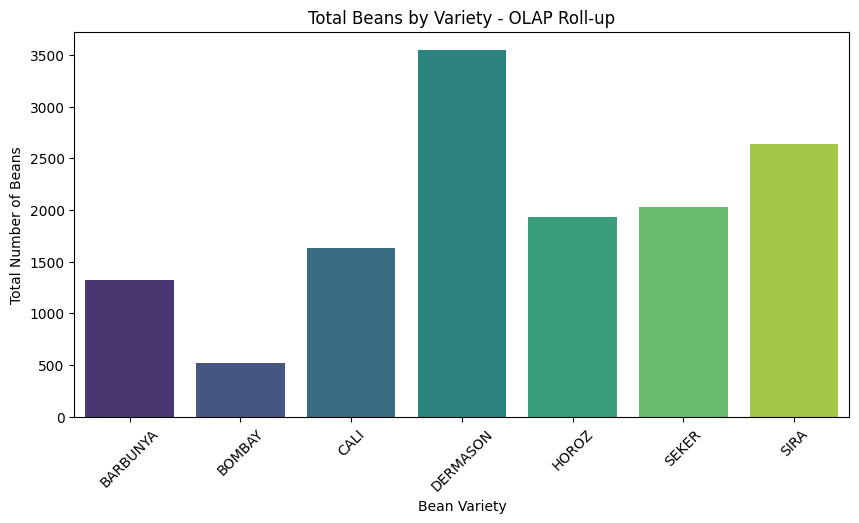

In [23]:
# OLAP Roll-up Visualization

plt.figure(figsize=(10, 5))

sns.barplot(
    data=rollup_result,
    x='Class_Name',
    y='Total_Beans',
    hue='Class_Name',
    legend=False,
    palette='viridis'
)

plt.title("Total Beans by Variety - OLAP Roll-up")
plt.xlabel("Bean Variety")
plt.ylabel("Total Number of Beans")
plt.xticks(rotation=45)

plt.show()


,Algorithm,Accuracy (%)
0,Decision Tree,89.203085
1,Rule-Based,81.821520
2,KNN,91.663606


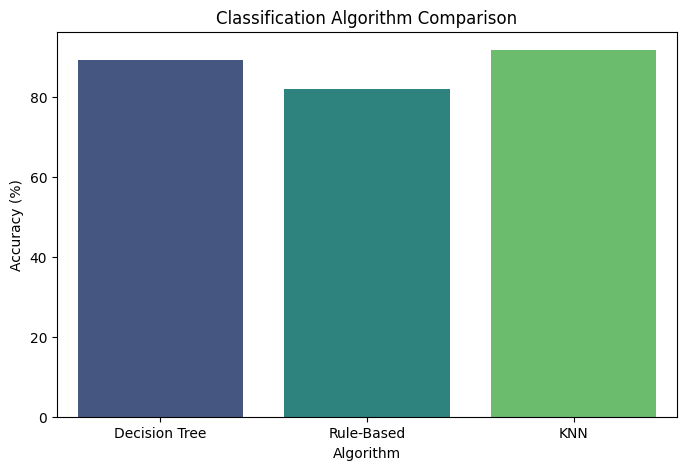

In [24]:
# Step 57: Classification Comparison

classification_results = pd.DataFrame({
    'Algorithm': [
        'Decision Tree',
        'Rule-Based',
        'KNN'
    ],
    'Accuracy (%)': [
        dt_accuracy * 100,
        rule_accuracy * 100,
        knn_accuracy * 100
    ]
})

display(classification_results)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=classification_results,
    x='Algorithm',
    y='Accuracy (%)',
    hue='Algorithm',
    legend=False,
    palette='viridis'
)

plt.title("Classification Algorithm Comparison")
plt.ylabel("Accuracy (%)")
plt.show()

In [25]:
# Step 58: Apriori vs FP-Growth

association_comparison = pd.DataFrame({
    'Algorithm': ['Apriori', 'FP-Growth'],
    'Frequent Itemsets': [
        len(frequent_itemsets_apriori),
        len(frequent_itemsets_fp)
    ],
    'Association Rules': [
        len(rules_apriori),
        len(rules_fp)
    ]
})

display(association_comparison)

association_comparison.set_index(
    'Algorithm'
).plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Apriori vs FP-Growth Comparison")
plt.ylabel("Number of Results")
plt.xticks(rotation=0)
plt.show()

NameError: name 'frequent_itemsets_apriori' is not defined

In [26]:
# Recreate Apriori and FP-Growth Results

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Select numerical attributes
association_df = df[
    ['Area', 'Perimeter', 'MajorAxisLength',
     'MinorAxisLength', 'AspectRation']
].copy()

# Convert numerical values into categories
categorical_df = pd.DataFrame(index=association_df.index)

for column in association_df.columns:
    categorical_df[column] = pd.qcut(
        association_df[column],
        q=3,
        labels=['Small', 'Medium', 'Large'],
        duplicates='drop'
    )

# Create transactions
transactions = []

for _, row in categorical_df.iterrows():
    transactions.append([
        f"{column}={value}"
        for column, value in row.items()
    ])

# One-hot encoding
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
transaction_array = te.fit(transactions).transform(transactions)

encoded_df = pd.DataFrame(
    transaction_array,
    columns=te.columns_
)

# Apriori
frequent_itemsets_apriori = apriori(
    encoded_df,
    min_support=0.05,
    use_colnames=True
)

# FP-Growth
frequent_itemsets_fp = fpgrowth(
    encoded_df,
    min_support=0.05,
    use_colnames=True
)

# Association rules
rules_apriori = association_rules(
    frequent_itemsets_apriori,
    metric="confidence",
    min_threshold=0.5
)

rules_fp = association_rules(
    frequent_itemsets_fp,
    metric="confidence",
    min_threshold=0.5
)

print("Apriori and FP-Growth Executed Successfully!")
print("Apriori Itemsets:", len(frequent_itemsets_apriori))
print("FP-Growth Itemsets:", len(frequent_itemsets_fp))

Apriori and FP-Growth Executed Successfully!
Apriori Itemsets: 184
FP-Growth Itemsets: 184


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Algorithm,Frequent Itemsets,Association Rules
0,Apriori,184,651
1,FP-Growth,184,651


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

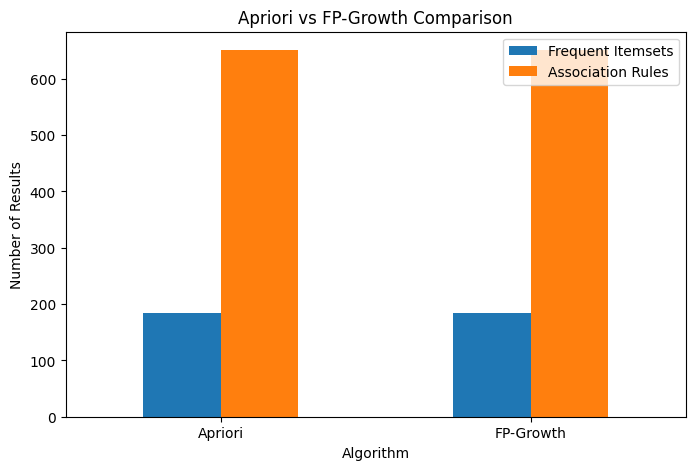

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [27]:
# Step 58: Apriori vs FP-Growth Comparison

association_comparison = pd.DataFrame({
    'Algorithm': ['Apriori', 'FP-Growth'],
    'Frequent Itemsets': [
        len(frequent_itemsets_apriori),
        len(frequent_itemsets_fp)
    ],
    'Association Rules': [
        len(rules_apriori),
        len(rules_fp)
    ]
})

display(association_comparison)

association_comparison.set_index(
    'Algorithm'
).plot(kind='bar', figsize=(8, 5))

plt.title("Apriori vs FP-Growth Comparison")
plt.ylabel("Number of Results")
plt.xticks(rotation=0)
plt.show()

In [28]:
# Step 59: Clustering Comparison

from sklearn.metrics import silhouette_score

clustering_results = []

for name, labels in {
    'K-Means': kmeans_labels,
    'Hierarchical': hierarchical_labels,
    'DBSCAN': dbscan_labels
}.items():

    unique_labels = set(labels)
    if -1 in unique_labels:
        unique_labels.remove(-1)

    if 2 <= len(unique_labels) < len(labels):
        score = silhouette_score(X_scaled, labels)
    else:
        score = np.nan

    clustering_results.append({
        'Algorithm': name,
        'Number of Clusters': len(unique_labels),
        'Silhouette Score': score
    })

clustering_comparison = pd.DataFrame(
    clustering_results
)

display(clustering_comparison)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,7,0.309380
1,Hierarchical,7,0.283855
2,DBSCAN,1,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [29]:
# Step 60: Final Performance Summary

print("========== PROJECT PERFORMANCE SUMMARY ==========")

print("\nCLASSIFICATION RESULTS")
display(classification_results)

print("\nASSOCIATION RULE RESULTS")
display(association_comparison)

print("\nCLUSTERING RESULTS")
display(clustering_comparison)

========== PROJECT PERFORMANCE SUMMARY ==========

CLASSIFICATION RESULTS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Algorithm,Accuracy (%)
0,Decision Tree,89.203085
1,Rule-Based,81.821520
2,KNN,91.663606



ASSOCIATION RULE RESULTS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Algorithm,Frequent Itemsets,Association Rules
0,Apriori,184,651
1,FP-Growth,184,651


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


CLUSTERING RESULTS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,7,0.309380
1,Hierarchical,7,0.283855
2,DBSCAN,1,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [30]:
# Step 61: Project Observations

print("DRY BEAN CLASSIFICATION - RESULTS")

print("\n1. Dataset Information")
print("Total Records:", len(df))
print("Total Features:", len(df.columns)-1)
print("Bean Varieties:", df['Class'].nunique())

print("\n2. Best Classification Algorithm")
print(classification_results.loc[
    classification_results['Accuracy (%)'].idxmax()
])

print("\n3. Association Mining")
print("Apriori Itemsets:",
      len(frequent_itemsets_apriori))
print("FP-Growth Itemsets:",
      len(frequent_itemsets_fp))

print("\n4. Clustering Results")
display(clustering_comparison)

print("\nResults Analysis Completed!")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

DRY BEAN CLASSIFICATION - RESULTS

1. Dataset Information
Total Records: 13611
Total Features: 16
Bean Varieties: 7

2. Best Classification Algorithm
Algorithm             KNN
Accuracy (%)    91.663606
Name: 2, dtype: object

3. Association Mining
Apriori Itemsets: 184
FP-Growth Itemsets: 184

4. Clustering Results


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,7,0.309380
1,Hierarchical,7,0.283855
2,DBSCAN,1,NaN



Results Analysis Completed!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag